# Linear Regression
**Unit 4 · Lesson 2 | PV Time Series**  
Instructor: Sepehr Shakibi  
[Applied Machine Learning and Deep Learning for Photovoltaics with Python](https://github.com/SepehrShakibi/applied-ml-dl-for-photovoltaics-with-python)

Predict `target_power_t_plus_1` from measurements at time **t**. Load the existing partitions, fit preprocessing and linear models on train, compare on validation, and evaluate the selected model on test.

## 1. Setup
Run from the project root. If running from a chapter folder, set `PROJECT_ROOT = os.path.abspath("..")`; otherwise use your project's absolute path.

**Colab:** mount Drive and set the project path. Runtime storage is temporary; keep inputs and saved artifacts on persistent storage.

In [3]:
# %pip install numpy pandas matplotlib scikit-learn joblib

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



In [6]:
!gdown --folder https://drive.google.com/drive/folders/1lFetK1YgncT5GPdLQFNrkuy8UWf-6881

Retrieving folder contents
Retrieving folder 14T5F5gwA0GGtPapainnN03f1IMhkXgec processed
Retrieving folder 1v372EjkxWn-8UdlhIvcPOS0ohwMXefZE pv_images
Processing file 1RFZRlUEIun3Z36gYpLClX8PRI4Og0Lql pv_images_test.csv
Processing file 1ZAqeFxVdPZu_uqfHT3Q7QRytm1CvbOnU pv_images_train.csv
Processing file 1pW98UOlS7Mh4LKHooN_1pzJjetJCnQFg pv_images_unknown.csv
Processing file 1hkMI_UN5FwmoSOfSXNuhz2zngOEjO-7k pv_images_validation.csv
Retrieving folder 1z994qLWlxE0mszwY1rLm8_1wQaso5gDB pv_time_series
Processing file 1DKNF0q9QHGBQSywBeNCC37bCEexxyWFq column_mapping.csv
Processing file 1bJlRxrYgcVEA1u383vq-F5g7E_lUQW3A pv_time_series_preprocessing.joblib
Processing file 1H5WyuYLz-Hye9SERAy1O3pu4grXmtLcJ pv_time_series_test_encoded.csv
Processing file 1ErXBDQHcCYa3aFv8rL0u7GTJkutuY5On pv_time_series_test_standardized.csv
Processing file 1IB0qv5K87J6MGmc8Q7SG-Q0lC745In1r pv_time_series_test.csv
Processing file 1nHbXSH4AxfpEwkwcqBfWOQVOI96SGaZQ pv_time_series_train_encoded.csv
Processing file

In [11]:
PROJECT_ROOT = os.path.abspath(".")
CONFIG = {
    "data_dir": os.path.join(PROJECT_ROOT, "data", "processed", "pv_time_series"),
    "output_dir": os.path.join(PROJECT_ROOT, "outputs", "04_02_linear_regression"),
    "random_state": 42,
    "sgd_epochs": 150,
    "learning_rate": 0.001,
}

## 2. Load the prepared data
Read the **raw, unscaled** split CSVs from Unit 3—not the `_encoded` or `_standardized` versions. The target and chronological partitions already exist. Do not split again, shift labels again, or repeat EDA and cleaning.

In [12]:
train_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_train.csv"))
validation_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_validation.csv"))
test_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_test.csv"))

print("Train:", train_data.shape)
print("Validation:", validation_data.shape)
print("Test:", test_data.shape)
display(train_data.head())

Train: (4955, 25)
Validation: (1061, 25)
Test: (1061, 25)


,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power,time_index,target_time_index,target_power_t_plus_1,target_class_t_plus_1
0,1,0.999852,1,1.0000,2,81,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,0,1,0.0,low
1,1,0.999852,2,0.9659,-1,86,0,900.2,10,0.0,...,0,0.0,0,0.0,0,0,1,2,0.0,low
2,1,0.999852,3,0.8660,0,87,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,2,3,0.0,low
3,1,0.999852,4,0.7071,-1,86,2,900.2,10,0.0,...,0,0.0,0,0.0,0,0,3,4,0.0,low
4,1,0.999852,5,0.5000,-1,86,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,4,5,0.0,low


## 3. Select inputs and target
Use an explicit list so neither future target enters the inputs. Time metadata stays outside the model. Exclude current `total_pv_power` from the inputs because the five panel powers already contain its sum; keep it as the persistence baseline.

All inputs must be available at forecast time. Confirm the definition and availability of `dewpoint` before operational use.

In [14]:
TARGET = "target_power_t_plus_1"
NUMERIC_FEATURES = [
    "cosine_of_day", "cosine_of_hour", "air_temperature", "dewpoint",
    "wind_speed", "air_pressure", "solar_radiation",
    "pv_1_cosine_value_of_the_solar_incidence_angle", "pv_1_power",
    "pv_2_cosine_value_of_the_solar_incidence_angle", "pv_2_power",
    "pv_3_cosine_value_of_the_solar_incidence_angle", "pv_3_power",
    "pv_4_cosine_value_of_the_solar_incidence_angle", "pv_4_power",
    "pv_5_cosine_value_of_the_solar_incidence_angle", "pv_5_power",
]
CATEGORICAL_FEATURES = ["weather_condition"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_train = train_data[FEATURES]
y_train = train_data[TARGET]
X_validation = validation_data[FEATURES]
y_validation = validation_data[TARGET]
X_test = test_data[FEATURES]
y_test = test_data[TARGET]

print("Number of inputs:", len(FEATURES))

Number of inputs: 18


## 4. Encoding and standardization inside the pipeline
1. Pass numerical measurements through unchanged and ordinal-encode weather.
2. Standardize the resulting input columns using training means and standard deviations:
   $z_j=(x_j-\mu_{j,\mathrm{train}})/\sigma_{j,\mathrm{train}}$.
3. Fit the regressor.

`pipeline.fit(X_train, y_train)` learns encoding, scaling and the model from **train only**. `pipeline.predict(...)` applies those same transformations without refitting. Each model receives a fresh pipeline.

Ordinal weather encoding follows Unit 3. It imposes numerical order and distances on nominal categories; scaling does not remove that limitation. Unseen categories receive code `-1`. One-hot encoding is an alternative to evaluate in a later lesson.

**Only X is scaled.** `y_train` is unchanged, so predictions already have the target's original units. Do not inverse-transform predictions with the input scaler. If the target itself were scaled, predictions would need its inverse transformation before original-unit evaluation; that is not done here.

In [15]:
linear_pipeline = Pipeline([
    ("encoder", ColumnTransformer([
        ("numeric", "passthrough", NUMERIC_FEATURES),
        ("weather", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        ), CATEGORICAL_FEATURES),
    ])),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])


In [ ]:
# linear_pipeline = Pipeline([
#     ("encoder", ColumnTransformer([
#         ("weather", OrdinalEncoder(
#             handle_unknown="use_encoded_value",
#             unknown_value=-1,
#         ), CATEGORICAL_FEATURES),
#     ], remainder="passthrough")),
#     ("scaler", StandardScaler()),
#     ("regressor", LinearRegression()),
# ])

## 5. Direct least squares
The linear prediction rule and training objective are:
\[
\hat y_{t+1}=b_0+\sum_{j=1}^{p}b_jx_{t,j},\qquad
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2.
\]
`LinearRegression` uses a direct numerical least-squares solver, not gradient descent. It has no learning rate. Avoid explicitly calculating $(X^T X)^{-1}$, especially with correlated features.

In [17]:
linear_pipeline.fit(X_train, y_train)

linear_regressor = linear_pipeline.named_steps["regressor"]

print("Intercept:", linear_regressor.intercept_)
print("Input matrix rank:", linear_regressor.rank_)


Intercept: 282.63390514631686
Input matrix rank: 18


### Inspect the training-fitted scaler
The encoder returns numeric features first, followed by weather, matching `FEATURES`. These statistics describe the encoded training inputs. They are reused for validation, test and new observations—not recomputed.

In [18]:
scaler = linear_pipeline.named_steps["scaler"]
display(pd.DataFrame({
    "feature": FEATURES,
    "training_mean": scaler.mean_,
    "training_scale": scaler.scale_,
}))

,feature,training_mean,training_scale
0,cosine_of_day,-0.117416,0.733127
1,cosine_of_hour,0.000397,0.707032
2,air_temperature,12.001615,9.996831
3,dewpoint,55.795156,21.598553
4,wind_speed,13.770333,8.581733
5,air_pressure,897.271685,4.836469
6,solar_radiation,203.320807,284.887692
7,pv_1_cosine_value_of_the_solar_incidence_angle,0.300443,0.373795
8,pv_1_power,58.933804,81.828886
9,pv_2_cosine_value_of_the_solar_incidence_angle,0.247850,0.352431


## 6. Iterative fitting with SGD
`SGDRegressor` updates coefficients using training observations. Set `penalty=None` to use the same unregularized squared-error objective as ordinary least squares. Standardized inputs help optimization.

Use a fixed learning rate and number of epochs for this lesson. `tol=None` disables early stopping. Training-row shuffling changes update order, not the chronological train/validation/test partition. A finite SGD run need not reach the direct solution.

In [19]:
from sklearn.base import clone

sgd_pipeline = clone(linear_pipeline).set_params(
    regressor=SGDRegressor(
        loss="squared_error",
        penalty=None,
        learning_rate="constant",
        eta0=CONFIG["learning_rate"],
        max_iter=CONFIG["sgd_epochs"],
        tol=None,
        shuffle=True,
        random_state=CONFIG["random_state"],
    )
)

sgd_pipeline.fit(X_train, y_train)

sgd_regressor = sgd_pipeline.named_steps["regressor"]
print("SGD epochs:", sgd_regressor.n_iter_)


SGD epochs: 150


### Learning curve
For an epoch-by-epoch view, train a separate `learning_curve_regressor` with `partial_fit`. Each call makes one training pass. This diagnostic model does not replace either fitted pipeline.

Use the SGD pipeline's already training-fitted preprocessing. Nothing is fitted on validation. These transformed arrays are only for the optimizer plots; the final pipelines still accept unscaled inputs.

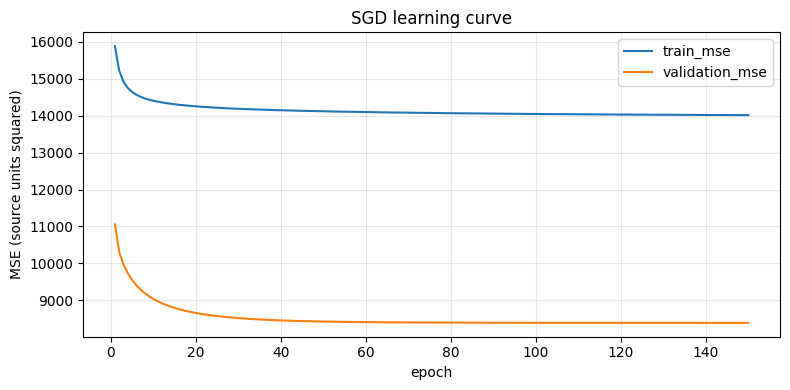

In [20]:
X_train_scaled = sgd_pipeline[:-1].transform(X_train)
X_validation_scaled = sgd_pipeline[:-1].transform(X_validation)

learning_curve_regressor = SGDRegressor(
    loss="squared_error", penalty=None,
    learning_rate="constant", eta0=CONFIG["learning_rate"],
    shuffle=True, random_state=CONFIG["random_state"],
)
training_history = []
for epoch in range(1, CONFIG["sgd_epochs"] + 1):
    learning_curve_regressor.partial_fit(X_train_scaled, y_train)
    training_history.append({
        "epoch": epoch,
        "train_mse": mean_squared_error(y_train, learning_curve_regressor.predict(X_train_scaled)),
        "validation_mse": mean_squared_error(y_validation, learning_curve_regressor.predict(X_validation_scaled)),
    })
training_history = pd.DataFrame(training_history)
ax = training_history.plot(x="epoch", y=["train_mse", "validation_mse"], figsize=(8, 4))
ax.set(title="SGD learning curve", ylabel="MSE (source units squared)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Effect of learning rate
Compare three rates using **training data only**. This illustrates optimization, not model selection. Small steps can be slow; large steps can oscillate or diverge. SGD loss need not decrease at every epoch. Stop a run if its loss becomes excessively large.

Stopped learning rate 0.1: excessive loss.


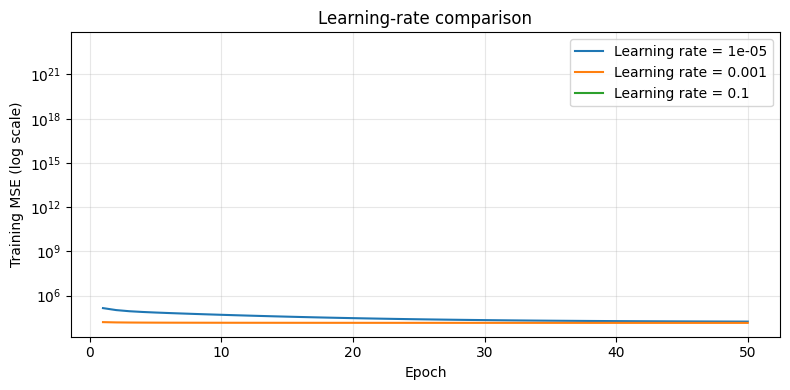

In [23]:
learning_rate_history = []
for learning_rate in (0.00001, 0.001, 0.1):
    learning_rate_regressor = SGDRegressor(
        loss="squared_error", penalty=None,
        learning_rate="constant", eta0=learning_rate,
        shuffle=True, random_state=CONFIG["random_state"],
    )
    for epoch in range(1, 51):
        learning_rate_regressor.partial_fit(X_train_scaled, y_train)
        prediction = learning_rate_regressor.predict(X_train_scaled)
        if not np.isfinite(prediction).all():
            print(f"Stopped learning rate {learning_rate}: non-finite predictions.")
            break
        mse = mean_squared_error(y_train, prediction)
        learning_rate_history.append({"learning_rate": learning_rate, "epoch": epoch, "mse": mse})
        if not np.isfinite(mse) or mse > 1e12 * max(float(y_train.var()), 1.0):
            print(f"Stopped learning rate {learning_rate}: excessive loss.")
            break

learning_rate_history = pd.DataFrame(learning_rate_history)
fig, ax = plt.subplots(figsize=(8, 4))
for learning_rate, rows in learning_rate_history.groupby("learning_rate"):
    ax.plot(rows["epoch"], rows["mse"], label=f"Learning rate = {learning_rate:g}")
ax.set(xlabel="Epoch", ylabel="Training MSE (log scale)", yscale="log", title="Learning-rate comparison")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Baselines and validation evaluation
Compare the two pipelines with the training-target mean and persistence: next-step power equals current `total_pv_power`.

- **MAE, RMSE:** original target units; lower is better.
- **MSE:** squared target units; lower is better.
- **R²:** higher is better; it can be negative.

The physical power unit has not been confirmed, so plots do not assume W or kW. **No inverse scaling is needed:** actual targets, predictions and persistence are already in the same original units.

In [32]:
mean_regressor = DummyRegressor(strategy="mean")
mean_regressor.fit(X_train, y_train)

mean_validation_prediction = mean_regressor.predict(X_validation)

mean_mae = mean_absolute_error(y_validation, mean_validation_prediction)
mean_mse = mean_squared_error(y_validation, mean_validation_prediction)
mean_rmse = np.sqrt(mean_mse)
mean_r2 = r2_score(y_validation, mean_validation_prediction)

print("Training mean baseline")
print("MAE:", mean_mae)
print("MSE:", mean_mse)
print("RMSE:", mean_rmse)
print("R2:", mean_r2)


Training mean baseline
MAE: 378.9767264475472
MSE: 200281.1509858138
RMSE: 447.5278214656758
R2: -0.02150109216213436


In [33]:
persistence_validation_prediction = (
    validation_data["total_pv_power"].to_numpy()
)

persistence_mae = mean_absolute_error(
    y_validation, persistence_validation_prediction
)
persistence_mse = mean_squared_error(
    y_validation, persistence_validation_prediction
)
persistence_rmse = np.sqrt(persistence_mse)
persistence_r2 = r2_score(
    y_validation, persistence_validation_prediction
)

print("Persistence baseline")
print("MAE:", persistence_mae)
print("MSE:", persistence_mse)
print("RMSE:", persistence_rmse)
print("R2:", persistence_r2)


Persistence baseline
MAE: 99.97360980207351
MSE: 26801.80395852969
RMSE: 163.71256506001515
R2: 0.863301804084935


In [34]:
linear_validation_prediction = linear_pipeline.predict(X_validation)

linear_mae = mean_absolute_error(y_validation, linear_validation_prediction)
linear_mse = mean_squared_error(y_validation, linear_validation_prediction)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_validation, linear_validation_prediction)

print("Linear Regression")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)


Linear Regression
MAE: 56.01924635268761
MSE: 8091.402557419218
RMSE: 89.95222374916152
R2: 0.9587311311681413


In [35]:
sgd_validation_prediction = sgd_pipeline.predict(X_validation)

sgd_mae = mean_absolute_error(y_validation, sgd_validation_prediction)
sgd_mse = mean_squared_error(y_validation, sgd_validation_prediction)
sgd_rmse = np.sqrt(sgd_mse)
sgd_r2 = r2_score(y_validation, sgd_validation_prediction)

print("SGD Regressor")
print("MAE:", sgd_mae)
print("MSE:", sgd_mse)
print("RMSE:", sgd_rmse)
print("R2:", sgd_r2)


SGD Regressor
MAE: 56.30176080488679
MSE: 7911.8589743213315
RMSE: 88.94863109863654
R2: 0.9596468637037417


In [36]:
validation_results = pd.DataFrame({
    "Model": [
        "Training mean",
        "Persistence",
        "LinearRegression",
        "SGDRegressor",
    ],
    "MAE": [
        mean_mae,
        persistence_mae,
        linear_mae,
        sgd_mae,
    ],
    "MSE": [
        mean_mse,
        persistence_mse,
        linear_mse,
        sgd_mse,
    ],
    "RMSE": [
        mean_rmse,
        persistence_rmse,
        linear_rmse,
        sgd_rmse,
    ],
    "R2": [
        mean_r2,
        persistence_r2,
        linear_r2,
        sgd_r2,
    ],
})

display(validation_results)


,Model,MAE,MSE,RMSE,R2
0,Training mean,378.976726,200281.150986,447.527821,-0.021501
1,Persistence,99.973610,26801.803959,163.712565,0.863302
2,LinearRegression,56.019246,8091.402557,89.952224,0.958731
3,SGDRegressor,56.301761,7911.858974,88.948631,0.959647


## 8. Coefficients
The coefficients refer to **standardized** inputs: a one-training-standard-deviation increase in an input changes the prediction by its coefficient in target units, holding other inputs fixed. The intercept corresponds to all standardized inputs being zero.

These are conditional associations, not causal effects. Correlated inputs can make coefficients unstable; their magnitudes alone are not reliable feature importance. Ordinal weather coefficients also inherit the artificial ordering of its codes.

,feature,coefficient
0,numeric__cosine_of_day,-31.500202
1,numeric__cosine_of_hour,-49.723389
2,numeric__air_temperature,-31.763123
3,numeric__dewpoint,11.684927
4,numeric__wind_speed,-4.364854
5,numeric__air_pressure,1.693762
6,numeric__solar_radiation,91.886286
7,numeric__pv_1_cosine_value_of_the_solar_incide...,-157.924399
8,numeric__pv_1_power,10.558014
9,numeric__pv_2_cosine_value_of_the_solar_incide...,49.276994


Intercept: [286.76995758]


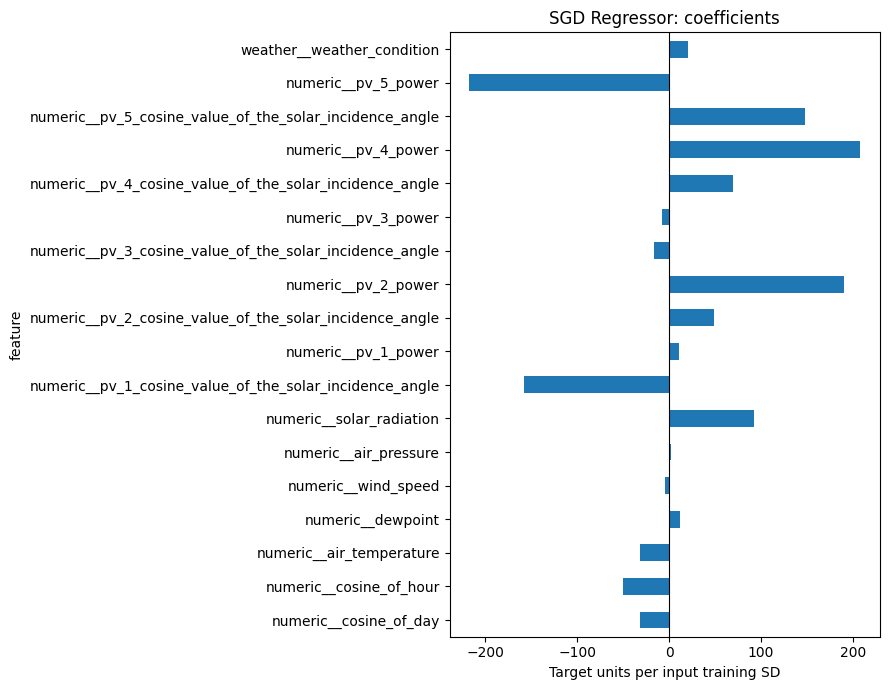

In [37]:
sgd_regressor = sgd_pipeline.named_steps["regressor"]

feature_names = (
    sgd_pipeline.named_steps["encoder"].get_feature_names_out()
)

coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": sgd_regressor.coef_,
})

display(coefficients)
print("Intercept:", sgd_regressor.intercept_)

ax = coefficients.set_index("feature")["coefficient"].plot.barh(
    figsize=(9, 7)
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title="SGD Regressor: coefficients",
    xlabel="Target units per input training SD",
)

plt.tight_layout()
plt.show()


## 9. Validation error analysis
Residual = actual − predicted. Positive residuals indicate underprediction. Patterns can reveal missing nonlinear relationships or temporal structure. Negative power forecasts are possible; do not silently clip predictions.

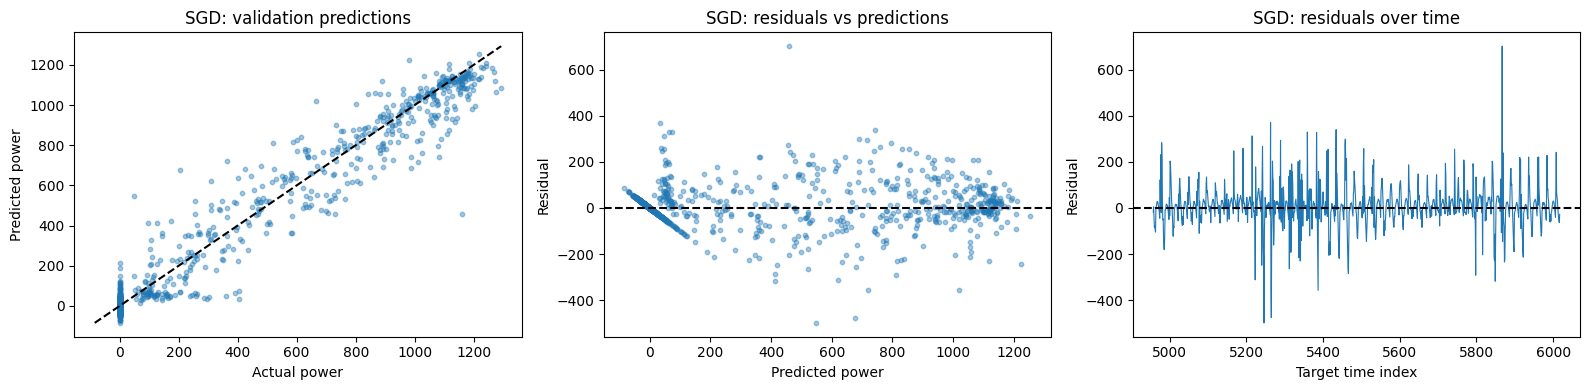

Negative validation predictions: 344


In [38]:
sgd_validation_prediction = sgd_pipeline.predict(X_validation)

sgd_validation_residual = (
    y_validation.to_numpy() - sgd_validation_prediction
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Actual vs predicted
axes[0].scatter(
    y_validation,
    sgd_validation_prediction,
    s=10,
    alpha=0.4,
)

low = min(y_validation.min(), sgd_validation_prediction.min())
high = max(y_validation.max(), sgd_validation_prediction.max())

axes[0].plot([low, high], [low, high], "k--")
axes[0].set(
    xlabel="Actual power",
    ylabel="Predicted power",
    title="SGD: validation predictions",
)

# Residuals vs predicted
axes[1].scatter(
    sgd_validation_prediction,
    sgd_validation_residual,
    s=10,
    alpha=0.4,
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(
    xlabel="Predicted power",
    ylabel="Residual",
    title="SGD: residuals vs predictions",
)

# Residuals over time
axes[2].plot(
    validation_data["target_time_index"],
    sgd_validation_residual,
    linewidth=0.8,
)
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set(
    xlabel="Target time index",
    ylabel="Residual",
    title="SGD: residuals over time",
)

plt.tight_layout()
plt.show()

print(
    "Negative validation predictions:",
    int((sgd_validation_prediction < 0).sum()),
)


## 10. Final test evaluation
Model selection is complete. Evaluate the selected pipeline and baselines once on test. Do not revise the model based on test performance. Keep the train-fitted pipeline unchanged so the saved artifact matches this evaluation.

In [39]:
mean_test_prediction = mean_regressor.predict(X_test)

mean_test_mae = mean_absolute_error(y_test, mean_test_prediction)
mean_test_mse = mean_squared_error(y_test, mean_test_prediction)
mean_test_rmse = np.sqrt(mean_test_mse)
mean_test_r2 = r2_score(y_test, mean_test_prediction)

print("Training mean — Test")
print("MAE:", mean_test_mae)
print("MSE:", mean_test_mse)
print("RMSE:", mean_test_rmse)
print("R2:", mean_test_r2)


Training mean — Test
MAE: 365.30138408732313
MSE: 188472.9895030628
RMSE: 434.1347596116473
R2: -0.002314937918678872


In [40]:
persistence_test_prediction = (
    test_data["total_pv_power"].to_numpy()
)

persistence_test_mae = mean_absolute_error(
    y_test, persistence_test_prediction
)
persistence_test_mse = mean_squared_error(
    y_test, persistence_test_prediction
)
persistence_test_rmse = np.sqrt(persistence_test_mse)
persistence_test_r2 = r2_score(
    y_test, persistence_test_prediction
)

print("Persistence — Test")
print("MAE:", persistence_test_mae)
print("MSE:", persistence_test_mse)
print("RMSE:", persistence_test_rmse)
print("R2:", persistence_test_r2)


Persistence — Test
MAE: 97.01225259189444
MSE: 30167.681432610745
RMSE: 173.68846085048582
R2: 0.8395657763905403


In [41]:
linear_test_prediction = linear_pipeline.predict(X_test)

linear_test_mae = mean_absolute_error(y_test, linear_test_prediction)
linear_test_mse = mean_squared_error(y_test, linear_test_prediction)
linear_test_rmse = np.sqrt(linear_test_mse)
linear_test_r2 = r2_score(y_test, linear_test_prediction)

print("Linear Regression — Test")
print("MAE:", linear_test_mae)
print("MSE:", linear_test_mse)
print("RMSE:", linear_test_rmse)
print("R2:", linear_test_r2)


Linear Regression — Test
MAE: 81.05917687938879
MSE: 16370.08908476156
RMSE: 127.94564894814344
R2: 0.9129425130466804


In [42]:
sgd_test_prediction = sgd_pipeline.predict(X_test)

sgd_test_mae = mean_absolute_error(y_test, sgd_test_prediction)
sgd_test_mse = mean_squared_error(y_test, sgd_test_prediction)
sgd_test_rmse = np.sqrt(sgd_test_mse)
sgd_test_r2 = r2_score(y_test, sgd_test_prediction)

print("SGD Regressor — Test")
print("MAE:", sgd_test_mae)
print("MSE:", sgd_test_mse)
print("RMSE:", sgd_test_rmse)
print("R2:", sgd_test_r2)


SGD Regressor — Test
MAE: 82.13867236663512
MSE: 16801.62510880108
RMSE: 129.62108280986192
R2: 0.910647568798779


In [43]:
test_results = pd.DataFrame({
    "Model": [
        "Training mean",
        "Persistence",
        "LinearRegression",
        "SGDRegressor",
    ],
    "MAE": [
        mean_test_mae,
        persistence_test_mae,
        linear_test_mae,
        sgd_test_mae,
    ],
    "MSE": [
        mean_test_mse,
        persistence_test_mse,
        linear_test_mse,
        sgd_test_mse,
    ],
    "RMSE": [
        mean_test_rmse,
        persistence_test_rmse,
        linear_test_rmse,
        sgd_test_rmse,
    ],
    "R2": [
        mean_test_r2,
        persistence_test_r2,
        linear_test_r2,
        sgd_test_r2,
    ],
})

display(test_results)


,Model,MAE,MSE,RMSE,R2
0,Training mean,365.301384,188472.989503,434.134760,-0.002315
1,Persistence,97.012253,30167.681433,173.688461,0.839566
2,LinearRegression,81.059177,16370.089085,127.945649,0.912943
3,SGDRegressor,82.138672,16801.625109,129.621083,0.910648


In [44]:
prediction_table = test_data[
    ["time_index", "target_time_index", TARGET]
].copy()

prediction_table["mean_prediction"] = mean_test_prediction
prediction_table["persistence_prediction"] = persistence_test_prediction
prediction_table["linear_prediction"] = linear_test_prediction
prediction_table["sgd_prediction"] = sgd_test_prediction

prediction_table["sgd_residual"] = (
    y_test.to_numpy() - sgd_test_prediction
)

display(prediction_table.head(10))


,time_index,target_time_index,target_power_t_plus_1,mean_prediction,persistence_prediction,linear_prediction,sgd_prediction,sgd_residual
0,6018,6019,0.0,282.633905,0,10.770475,9.546282,-9.546282
1,6019,6020,0.0,282.633905,0,9.681124,7.425797,-7.425797
2,6020,6021,0.0,282.633905,0,-1.044103,-4.260498,4.260498
3,6021,6022,0.0,282.633905,0,-8.079068,-12.022777,12.022777
4,6022,6023,0.0,282.633905,0,-20.952206,-25.740841,25.740841
5,6023,6024,0.0,282.633905,0,-30.904484,-36.424007,36.424007
6,6024,6025,0.0,282.633905,0,-34.793456,-40.590208,40.590208
7,6025,6026,0.0,282.633905,0,-24.495759,-29.798989,29.798989
8,6026,6027,0.0,282.633905,0,-9.998840,-14.730903,14.730903
9,6027,6028,0.0,282.633905,0,1.437958,-2.345268,2.345268


## 11. Save the complete pipeline and reuse it
The artifact contains the fitted weather encoder, scaler and regressor. It accepts **unencoded, unscaled** feature rows with the same schema as the raw split CSVs. Do not preprocess these rows again or load the Unit 3 scaler.

Outputs go to a separate lesson folder; rerunning replaces lesson artifacts, not source CSVs. Load only trusted joblib files.

In [45]:
os.makedirs(CONFIG["output_dir"], exist_ok=True)
model_path = os.path.join(CONFIG["output_dir"], "linear_regression_pipeline.joblib")
artifact = {
    "pipeline": selected_pipeline,
    "model_name": selected_name,
    "feature_columns": FEATURES,
    "target_column": TARGET,
    "input_format": "raw, unencoded, unscaled features",
    "target_scaled": False,
    "config": CONFIG,
    "versions": {"scikit_learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
joblib.dump(artifact, model_path)
validation_results.to_csv(os.path.join(CONFIG["output_dir"], "validation_metrics.csv"))
test_results.to_csv(os.path.join(CONFIG["output_dir"], "test_metrics.csv"))
prediction_table.to_csv(os.path.join(CONFIG["output_dir"], "test_predictions.csv"), index=False)
coefficients.to_csv(os.path.join(CONFIG["output_dir"], "coefficients.csv"), index=False)
training_history.to_csv(os.path.join(CONFIG["output_dir"], "sgd_learning_curve.csv"), index=False)

loaded_artifact = joblib.load(model_path)
new_observations = test_data.loc[:, loaded_artifact["feature_columns"]].head(5)
new_predictions = loaded_artifact["pipeline"].predict(new_observations)
np.testing.assert_allclose(new_predictions, test_prediction[:5])
print("Reload check passed. Predictions in original target units:")
print(new_predictions)
print("Saved to:", CONFIG["output_dir"])

Reload check passed. Predictions in original target units:
[  9.54628202   7.42579658  -4.26049757 -12.02277729 -25.74084132]
Saved to: /content/outputs/04_02_linear_regression


## 12. Summary
- Encoding, scaling and fitting belong to one train-fitted pipeline.
- Only inputs were scaled; evaluation already uses original target units.
- Direct least squares and SGD optimize a linear rule using different methods.
- Compare against persistence, not just against another learned model.
- Nonlinearity, outliers, collinearity, ordinal weather encoding and extrapolation limit this baseline.
- A chronological test supports this forecasting setup, not transfer to unseen PV systems.
- Future temporal cross-validation must refit the **whole pipeline** within each training fold.

**Practice:** using validation only, explain whether SGD approached the direct solution and whether either model improved over persistence. Do not tune against the final test.